# 03 · Prophet

Prophet dengan regresor `covid` dan `lebaran` (informasi yang sama dengan SARIMAX, supaya perbandingannya adil).

**Parameter tidak di-tuning.** Untuk tuning yang sah, dibutuhkan data validasi terpisah dari data uji. Satu-satunya kandidat adalah 2022, tapi 2022 adalah tahun pemulihan pasca-COVID yang tidak mewakili kondisi normal (lihat bagian 3). Karena itu dipakai nilai default library.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.forecasting import *

quiet()
setup_plot()
pd.options.display.float_format = '{:,.2f}'.format

In [2]:
y = load_passengers()
train, test = y[:'2022'], y['2023']
prophet_pred, model = fit_predict_prophet(train, 12)
pd.Series(metrics(test, prophet_pred))

MAE        196,080.49
RMSE       214,892.66
MAPE (%)        15.16
dtype: float64

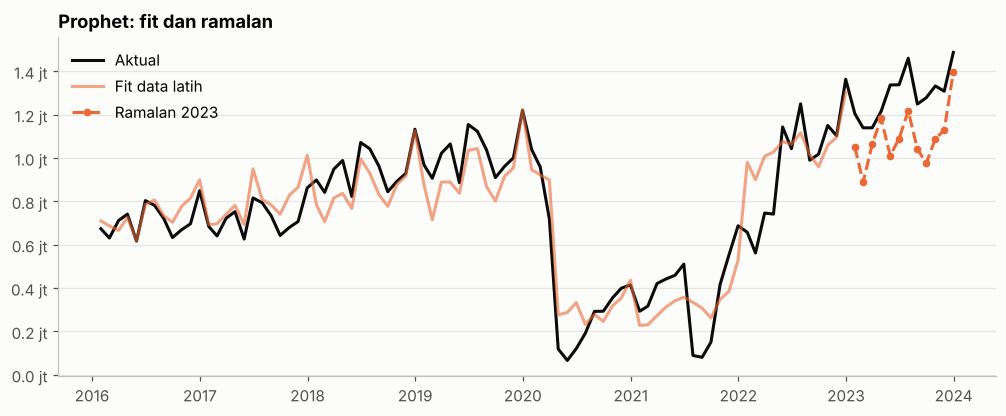

In [3]:
from prophet import Prophet
full = model.predict(model.history)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(y.index, y.values, color=COLORS['Aktual'], label='Aktual')
ax.plot(full['ds'], full['yhat'], color=COLORS['Prophet'], alpha=0.6, label='Fit data latih')
ax.plot(test.index, prophet_pred, color=COLORS['Prophet'], ls='--', marker='o', ms=4, label='Ramalan 2023')
million_axis(ax); ax.legend(loc='upper left')
ax.set_title('Prophet: fit dan ramalan')
plt.show()

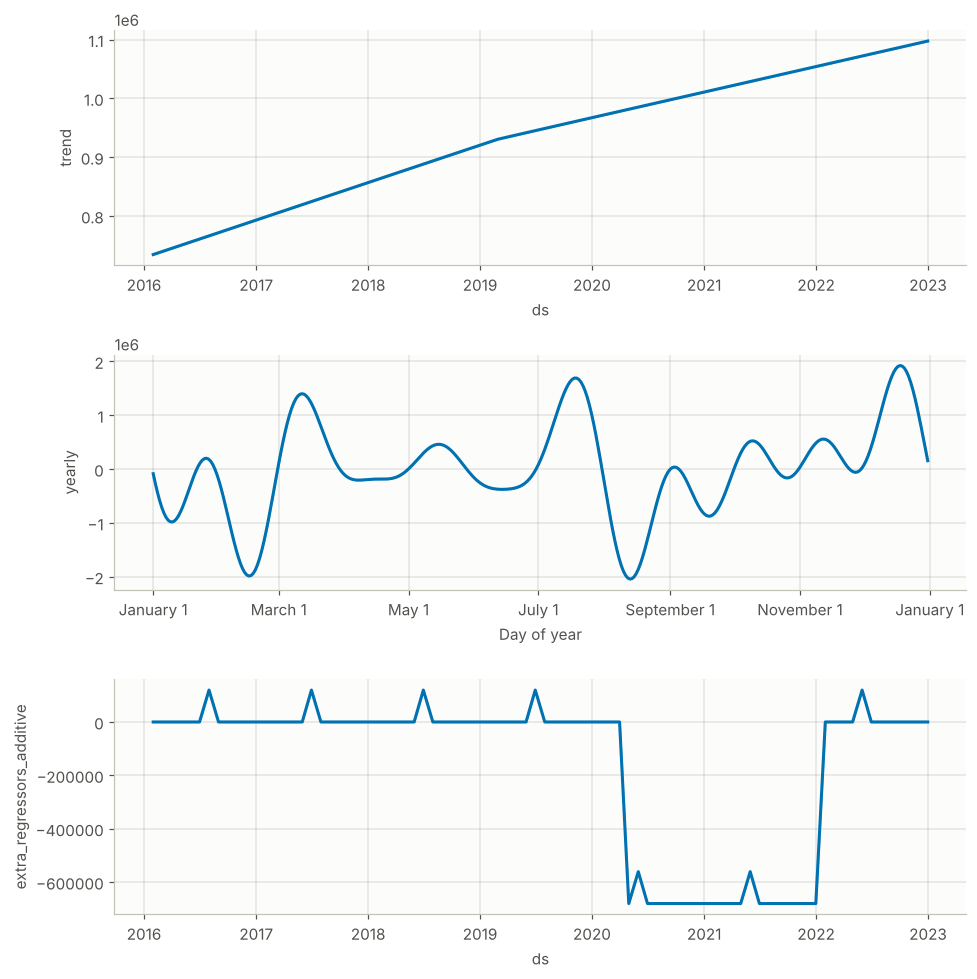

In [4]:
fig = model.plot_components(model.predict(model.history))
plt.show()

Prophet meremehkan hampir semua bulan 2023. Grafik komponen menunjukkan dua sebabnya:

1. **Tren hampir berupa garis lurus** dari 2016 sampai 2022 (sekitar 1,1 juta di akhir 2022). Tren itu tidak menangkap bahwa penumpang 2023 sudah melampaui level sebelum COVID. Efek COVID diserap regresor `covid`, sehingga tren "tidak tahu" ada lonjakan setelahnya.
2. **Komponen musiman tahunan berayun ±2 juta**, jauh lebih besar dari datanya sendiri. Prophet membentuk musiman dari kurva harian (deret Fourier), padahal datanya hanya satu titik per bulan. Di antara titik-titik itu kurvanya bebas berayun. Ini masalah umum memakai Prophet untuk data bulanan, dan salah satu alasan Prophet kalah dari SARIMAX di sini.

## 2. Seberapa sensitif Prophet terhadap parameter?

Tabel ini **bukan** untuk memilih parameter. Tujuannya menunjukkan kenapa memilih parameter berdasarkan skor data uji itu berbahaya.

In [5]:
rows = []
for cps in [0.001, 0.01, 0.05, 0.1, 0.5]:
    pred, _ = fit_predict_prophet(train, 12, changepoint_prior_scale=cps)
    rows.append({'changepoint_prior_scale': cps, **metrics(test, pred)})
sens = pd.DataFrame(rows).astype({'changepoint_prior_scale': str}).set_index('changepoint_prior_scale')
sens

,MAE,RMSE,MAPE (%)
changepoint_prior_scale,,,
0.001,"183,264.43","204,943.73",14.20
0.01,"177,003.02","197,751.52",13.69
0.05,"196,080.49","214,892.66",15.16
0.1,"235,486.04","251,312.79",18.22
0.5,"125,957.45","144,122.14",9.79


MAPE di data uji berubah dari sekitar 9% sampai 18% hanya karena satu parameter. Di skripsi, parameter dipilih berdasarkan skor 2023 (bahkan dengan Bayesian optimization yang targetnya MAPE 2023). Skor yang didapat dengan cara itu adalah skor **terbaik dari banyak percobaan pada data yang sama**, bukan perkiraan kinerja model di data baru.

## 3. Kenapa 2022 tidak bisa dipakai sebagai data validasi

In [6]:
tr_v, va = y[:'2021'], y['2022']
rows = []
for cps in [0.01, 0.05, 0.5]:
    pred, _ = fit_predict_prophet(tr_v, 12, changepoint_prior_scale=cps)
    rows.append({'changepoint_prior_scale': cps, 'MAPE validasi 2022 (%)': metrics(va, pred)['MAPE (%)']})
pd.DataFrame(rows).set_index('changepoint_prior_scale')

,MAPE validasi 2022 (%)
changepoint_prior_scale,
0.01,41.05
0.05,41.05
0.50,43.03


Dilatih sampai 2021 (masih masa COVID), semua konfigurasi gagal meramal 2022 dengan MAPE sekitar 40%. Skor validasi ini tidak membedakan konfigurasi yang baik dan yang buruk, jadi tidak berguna untuk tuning. Inilah batasan nyata dari data ini: **hanya ada satu tahun normal pasca-COVID di data latih**.

In [7]:
pd.DataFrame({'Prophet': prophet_pred}, index=test.index).to_csv('../data/processed/ramalan_prophet.csv', index_label='bulan')
sens.to_csv('../data/processed/prophet_sensitivitas.csv')